# Contrastive SSL for histopathologic cancer detection using Pcam dataset
- dataset: PatchCamelyon
- Model: SSL [ SimCLR ] + linear layer on top
- Optimizer: AdamW
- Training Set: 58k test_file images + 80k train_file images
- Linear Eval Set: 70k train_file images
- Eval Set: 70k train_file images

### Data Augmentations
- color jitter : will make up for staining variations of cells
- inversions: they are biologically invariant
- rotations: biologically invariant
- blurr: mild; just for focus differences
- no cropping: its already 96x96, cropping and resizing will make it lose info

## Imports

In [ ]:
!pip install kagglehub
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 24.8 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import os
from torch.utils.data import Dataset,DataLoader
from PIL import Image
import matplotlib.pyplot as plt
import torchvision
import torchvision.transforms.functional as TF
import torchvision.transforms.v2 as T
import torchmetrics.functional as TMF
import itertools
import kagglehub

In [ ]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(42)

## Data Augmentations
- Color Jitter
- Inversions
- blurr

In [ ]:
CJ=T.RandomApply([T.ColorJitter(0.4,0.4,0.2,0.1)],p=0.8)
HINV=T.RandomHorizontalFlip(p=0.5)
VINV=T.RandomVerticalFlip(p=0.5)
BL=T.RandomApply([T.GaussianBlur(9,(0.1,1.0))],p=0.5)
norm=T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225])
def denorm(img):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return (img * std + mean).clamp(0, 1)
transformation_pipeline=torchvision.transforms.Compose([
    CJ,
    HINV,
    VINV,
    BL,
])

In [ ]:
def data_augmentation(z):
    z=transformation_pipeline(z)

    z=norm(z)
    return z

## Dataset Loader

In [ ]:
kagglehub.login()
# KGAT_acfbbf89388585d8871087cc0855d3c5

Kaggle credentials set.
Kaggle credentials successfully validated.


In [ ]:
path = kagglehub.competition_download('histopathologic-cancer-detection')

print("Path to competition files:", path)

100%|██████████| 6.31G/6.31G [00:57<00:00, 118MB/s] 

Extracting files...


Path to competition files: /root/.cache/kagglehub/competitions/histopathologic-cancer-detection


In [ ]:
train_list=[]
layer_list=[]
test_list=[]
labels={}
labels_df=pd.read_csv("/root/.cache/kagglehub/competitions/histopathologic-cancer-detection/train_labels.csv")
labels=pd.Series(labels_df.label.values,index=labels_df.id)
input_dir="/root/.cache/kagglehub/competitions/histopathologic-cancer-detection/test"
for file in sorted(os.listdir(input_dir)):
            if file.endswith(".tif"):
                train_list.append(f"{input_dir}/{file}")
i=0
input_dir="/root/.cache/kagglehub/competitions/histopathologic-cancer-detection/train"
for file in sorted(os.listdir(input_dir)):
            if file.endswith(".tif"):
                i+=1
                if(i<=80000):
                    train_list.append(f"{input_dir}/{file}")
                elif(i<150000):
                    layer_list.append(f"{input_dir}/{file}")
                else:
                    test_list.append(f"{input_dir}/{file}")

print("Train List Size: ",len(train_list))
print("Layer List Size: ",len(layer_list))
print("Test List Size: ",len(test_list))

Train List Size:  137458
Layer List Size:  69999
Test List Size:  70026


In [ ]:
labels_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220025 entries, 0 to 220024
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   id      220025 non-null  object
 1   label   220025 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 3.4+ MB


In [ ]:
class DT(Dataset):
    def __init__(self,train,label_present,labels=None,p=100):
        if label_present and p<100:
            self.indexes=random.sample(range(0,len(train)),(len(train)//100)*p)
        self.input_dir=input_dir
        if label_present:
            if p==100:
                self.img_address=train
            else:
                self.img_address=[train[i] for i in self.indexes]
        else:
            self.img_address=train

        self.labels_present=label_present
        self.labels=labels
        print(f"{len(self.img_address)} images loaded successfully")
    def __len__(self):
        return len(self.img_address)
    def __getitem__(self,idx):
        img_add=self.img_address[idx]
        img=Image.open(img_add).convert("RGB")
        # img=Image.open(img_add)
        if self.labels_present:
            y=self.labels[img_add[-44:-4:1]]
            return norm(TF.to_tensor(img)),y

        return TF.to_tensor(img),data_augmentation(TF.to_tensor(img))

In [ ]:
train_DS=DT(train_list,False)
linear_DS=DT(layer_list,True,labels,p=100)
eval_DS=DT(test_list,True,labels,p=100)

137458 images loaded successfully
69999 images loaded successfully
70026 images loaded successfully


In [ ]:
my_dataloader = DataLoader(
    dataset=train_DS,
    batch_size=64,
    shuffle=True,
    num_workers=4,
    pin_memory=False,
    persistent_workers=True
)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


## Image visualisation

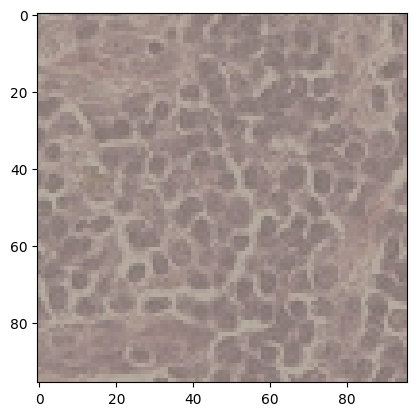

In [ ]:
image1,_=train_DS.__getitem__(2000)
plt.imshow(denorm(image1).permute(1,2,0).numpy())

label =  0


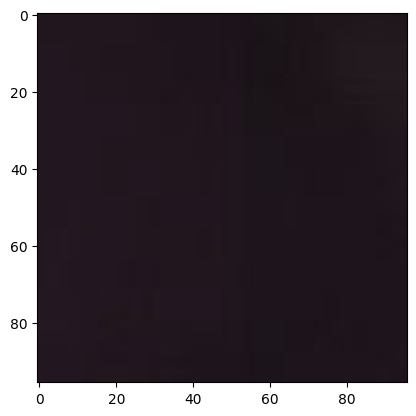

In [ ]:
image1,y1=linear_DS.__getitem__(4)
print("label = ",y1)
plt.imshow(denorm(image1).permute(1,2,0).numpy())

label =  0


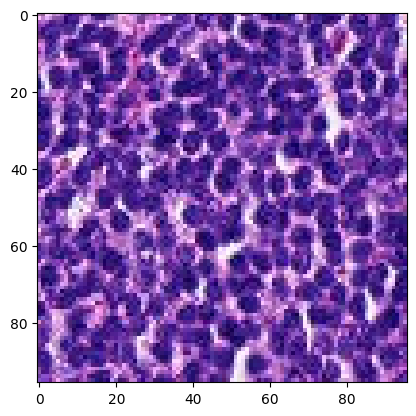

In [ ]:
image1,y1=linear_DS.__getitem__(9)
print("label = ",y1)
plt.imshow(denorm(image1).permute(1,2,0).numpy())

## Metrics

In [ ]:
def ece(y_real,y_result,bins=10):
    bin_boundaries = np.linspace(0, 1, bins + 1)
    bin_lowers = bin_boundaries[:-1]
    bin_uppers = bin_boundaries[1:]
    y_res_copy=y_result.clone().cpu().numpy()
    y_res_copy_labels=np.where(y_res_copy>=0.5,1,0)
    y_real_copy=y_real.clone().cpu().numpy()

    ece = 0
    for bin_lower, bin_upper in zip(bin_lowers, bin_uppers):
      if bin_upper==1:
        in_bin=(y_res_copy>=bin_lower)
      else:
        in_bin=(y_res_copy>=bin_lower) & (y_res_copy<bin_upper)

      y_res_bin=y_res_copy[in_bin]
      y_real_bin=y_real_copy[in_bin]
      y_res_labels_bin=y_res_copy_labels[in_bin]
      if len(y_res_bin)==0:continue
      acc=np.mean(y_real_bin==y_res_labels_bin)
      conf=y_res_bin.mean()
      ece += np.abs(acc - conf)* len(y_res_bin)
    return ece/len(y_real)


In [ ]:
def metrics_display(y_real,y_result):
    acc=TMF.accuracy(y_result, y_real, task='binary')
    f1=TMF.f1_score(y_result, y_real, task='binary')
    roc=TMF.auroc(y_result, y_real,task='binary')
    spec=TMF.specificity(y_result, y_real,task='binary')
    recall=TMF.recall(y_result, y_real,task='binary')
    ece_score=ece(y_real,y_result)
    print(f"Accuracy : {acc}")
    print(f"F1 Score : {f1}")
    print(f"AUC-ROC : {roc}")
    print(f"Specificity : {spec}")
    print(f"Recall : {recall}")
    print(f"ECE : {ece_score}")

def metrics_dict_creator(y_real,y_result):
    acc=TMF.accuracy(y_result, y_real, task='binary')
    f1=TMF.f1_score(y_result, y_real, task='binary')
    roc=TMF.auroc(y_result, y_real,task='binary')
    spec=TMF.specificity(y_result, y_real,task='binary')
    recall=TMF.recall(y_result, y_real,task='binary')
    ece_score=ece(y_real,y_result)
    return {
        "Accuracy" : acc,
        "F1 Score" : f1,
        "AUC-ROC" : roc,
        "Specificity" : spec,
        "Recall" : recall,
        "ECE" : ece_score
    }

## Loss Functions

In [ ]:
def NTXent_Loss(z,tau):
    n2=z.shape[0]
    n=n2//2

    z=F.normalize(z,dim=-1)
    sim=z @ z.T /tau

    pos=torch.arange(n2,device=z.device)

    positive_pos=pos^1

    mask=torch.eye(n2, dtype=torch.bool,device=z.device)
    sim.masked_fill_(mask, float('-inf'))

    log_soft=F.log_softmax(sim,dim=-1)
    loss=-log_soft[pos,positive_pos].mean()

    return loss

## Model

In [ ]:
class Encoder(nn.Module):
    def __init__(self,proj_dim=128):
        super().__init__()
        self.encoder=torchvision.models.resnet18(weights=None)
        self.encoder.conv1=nn.Conv2d(3,64,kernel_size=3,stride=1,padding=1,bias=False)
        self.encoder.maxpool=nn.Identity()
        self.encoder.fc=nn.Identity()

        self.projector=nn.Sequential(
            nn.Linear(512,512),
            nn.ReLU(),
            nn.Linear(512,proj_dim)
        )
    def forward(self,x):
        h=self.encoder(x)
        z=self.projector(h)
        return h,z

In [ ]:
SSLEncoder=Encoder().to(device)
optim=torch.optim.AdamW(SSLEncoder.parameters(),lr=5e-5,weight_decay=1e-5)
fullpath=os.path.join("/kaggle/working/","SSLEncoder.pth")
if os.path.exists(fullpath):
    SSLEncoder.load_state_dict(torch.load('SSLEncoder.pth',weights_only=True))
    print("Loaded last saved weights of encoder")
else:
    print("Loaded random weights of encoder: saved weights not found")

Loaded random weights of encoder: saved weights not found


## Model training loop

In [ ]:
loss_dict={}

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


| | | | | | | | | | 

Epoch : 0 # 10
Loss: 3.3984878063201904
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 20
Loss: 3.070030689239502
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 30
Loss: 2.964855194091797
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 40
Loss: 2.9303932189941406
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 50
Loss: 3.0136032104492188
--------------------
| | | | | | | | | | 

Epoch : 0 # 60
Loss: 3.070563316345215
--------------------
| | | | | | | | | | 

Epoch : 0 # 70
Loss: 2.8075084686279297
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 80
Loss: 2.7807273864746094
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 90
Loss: 2.922150135040283
--------------------
| | |

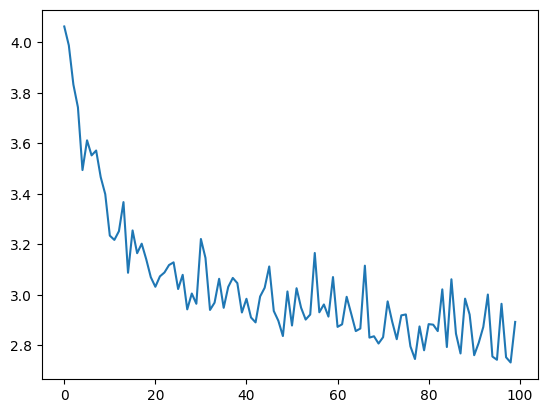

| | | | | | | | | | 

Epoch : 0 # 110
Loss: 2.8465213775634766
--------------------
| | | | | | | | | | 

Epoch : 0 # 120
Loss: 2.670012950897217
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 130
Loss: 2.78867244720459
--------------------
| | | | | | | | | | 

Epoch : 0 # 140
Loss: 2.779758930206299
--------------------
| | | | | | | | | | 

Epoch : 0 # 150
Loss: 2.598264694213867
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 160
Loss: 2.6464765071868896
--------------------
| | | | | | | | | | 

Epoch : 0 # 170
Loss: 2.738001823425293
--------------------
| | | | | | | | | | 

Epoch : 0 # 180
Loss: 2.685688018798828
--------------------
| | | | | | | | | | 

Epoch : 0 # 190
Loss: 2.607541084289551
--------------------
| | | | | | | | | | 

Epoch : 0 # 200
Loss: 2.6272735595703125
--------------------


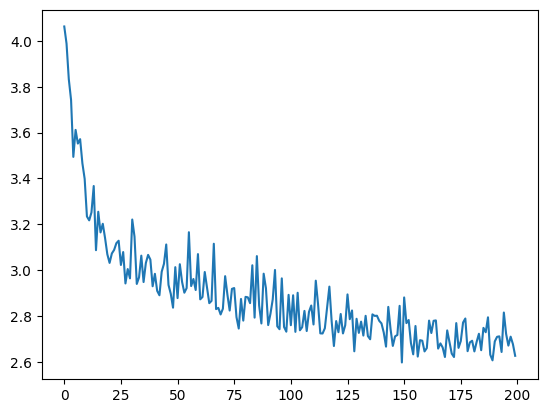

| | | | | | | | | | 

Epoch : 0 # 210
Loss: 2.738628387451172
--------------------
| | | | | | | | | | 

Epoch : 0 # 220
Loss: 2.7939624786376953
--------------------
| | | | | | | | | | 

Epoch : 0 # 230
Loss: 2.5899980068206787
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 240
Loss: 2.554250478744507
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 250
Loss: 2.710195779800415
--------------------
| | | | | | | | | | 

Epoch : 0 # 260
Loss: 2.6012630462646484
--------------------
| | | | | | | | | | 

Epoch : 0 # 270
Loss: 2.592540979385376
--------------------
| | | | | | | | | | 

Epoch : 0 # 280
Loss: 2.6643152236938477
--------------------
| | | | | | | | | | 

Epoch : 0 # 290
Loss: 2.5668232440948486
--------------------
| | | | | | | | | | 

Epoch : 0 # 300
Loss: 2.525233268737793
--------------------
saved SSLEncoder.pth
--------------------


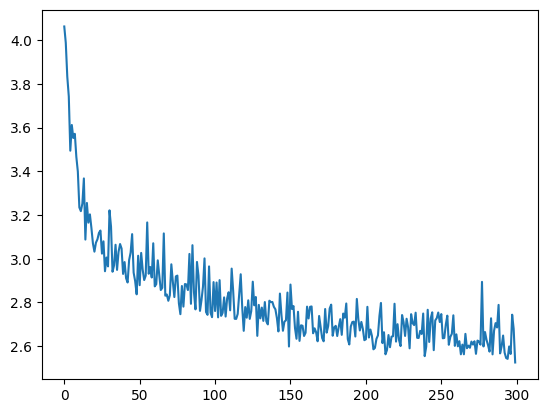

| | | | | | | | | | 

Epoch : 0 # 310
Loss: 2.632073402404785
--------------------
| | | | | | | | | | 

Epoch : 0 # 320
Loss: 2.689847946166992
--------------------
| | | | | | | | | | 

Epoch : 0 # 330
Loss: 2.675568103790283
--------------------
| | | | | | | | | | 

Epoch : 0 # 340
Loss: 2.6869115829467773
--------------------
| | | | | | | | | | 

Epoch : 0 # 350
Loss: 2.5758705139160156
--------------------
| | | | | | | | | | 

Epoch : 0 # 360
Loss: 2.6061439514160156
--------------------
| | | | | | | | | | 

Epoch : 0 # 370
Loss: 2.6599555015563965
--------------------
| | | | | | | | | | 

Epoch : 0 # 380
Loss: 2.503537178039551
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 390
Loss: 2.59688401222229
--------------------
| | | | | | | | | | 

Epoch : 0 # 400
Loss: 2.5174808502197266
--------------------


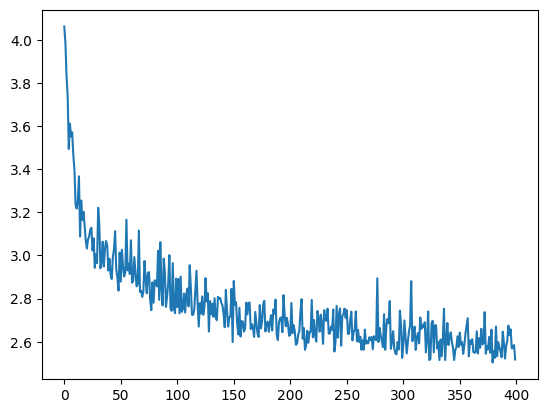

| | | | | | | | | | 

Epoch : 0 # 410
Loss: 2.4810471534729004
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 420
Loss: 2.585988998413086
--------------------
| | | | | | | | | | 

Epoch : 0 # 430
Loss: 2.551858901977539
--------------------
| | | | | | | | | | 

Epoch : 0 # 440
Loss: 2.669121265411377
--------------------
| | | | | | | | | | 

Epoch : 0 # 450
Loss: 2.5018038749694824
--------------------
| | | | | | | | | | 

Epoch : 0 # 460
Loss: 2.56453013420105
--------------------
| | | | | | | | | | 

Epoch : 0 # 470
Loss: 2.5687029361724854
--------------------
| | | | | | | | | | 

Epoch : 0 # 480
Loss: 2.5495200157165527
--------------------
| | | | | | | | | | 

Epoch : 0 # 490
Loss: 2.5601961612701416
--------------------
| | | | | | | | | | 

Epoch : 0 # 500
Loss: 2.6462502479553223
--------------------


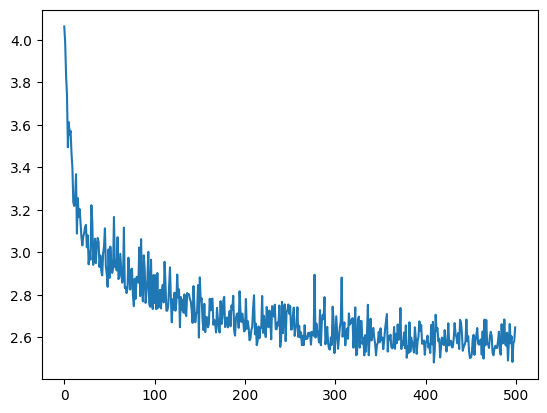

| | | | | | | | | | 

Epoch : 0 # 510
Loss: 2.58541202545166
--------------------
| | | | | | | | | | 

Epoch : 0 # 520
Loss: 2.708026885986328
--------------------
| | | | | | | | | | 

Epoch : 0 # 530
Loss: 2.5767662525177
--------------------
| | | | | | | | | | 

Epoch : 0 # 540
Loss: 2.529787063598633
--------------------
| | | | | | | | | | 

Epoch : 0 # 550
Loss: 2.622133493423462
--------------------
| | | | | | | | | | 

Epoch : 0 # 560
Loss: 2.4932913780212402
--------------------
| | | | | | | | | | 

Epoch : 0 # 570
Loss: 2.545647621154785
--------------------
| | | | | | | | | | 

Epoch : 0 # 580
Loss: 2.5077803134918213
--------------------
| | | | | | | | | | 

Epoch : 0 # 590
Loss: 2.5680062770843506
--------------------
| | | | | | | | | | 

Epoch : 0 # 600
Loss: 2.5629918575286865
--------------------


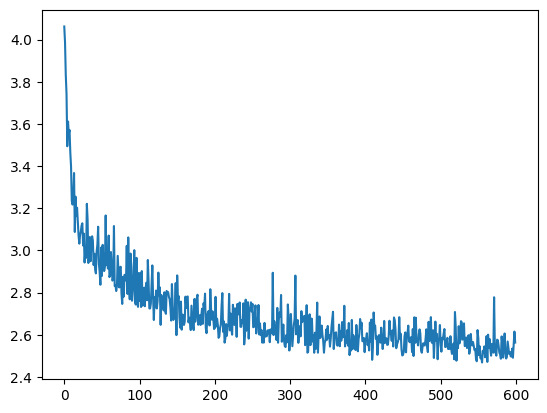

| | | | | | | | | | 

Epoch : 0 # 610
Loss: 2.4996495246887207
--------------------
| | | | | | | | | | 

Epoch : 0 # 620
Loss: 2.5291407108306885
--------------------
| | | | | | | | | | 

Epoch : 0 # 630
Loss: 2.476099729537964
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 640
Loss: 2.4954488277435303
--------------------
| | | | | | | | | | 

Epoch : 0 # 650
Loss: 2.540055513381958
--------------------
| | | | | | | | | | 

Epoch : 0 # 660
Loss: 2.524561882019043
--------------------
| | | | | | | | | | 

Epoch : 0 # 670
Loss: 2.528494358062744
--------------------
| | | | | | | | | | 

Epoch : 0 # 680
Loss: 2.4990615844726562
--------------------
| | | | | | | | | | 

Epoch : 0 # 690
Loss: 2.5020909309387207
--------------------
| | | | | | | | | | 

Epoch : 0 # 700
Loss: 2.560072422027588
--------------------


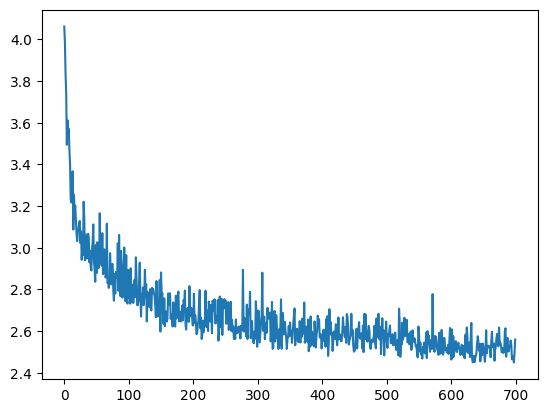

| | | | | | | | | | 

Epoch : 0 # 710
Loss: 2.4802873134613037
--------------------
| | | | | | | | | | 

Epoch : 0 # 720
Loss: 2.6486096382141113
--------------------
| | | | | | | | | | 

Epoch : 0 # 730
Loss: 2.4950568675994873
--------------------
| | | | | | | | | | 

Epoch : 0 # 740
Loss: 2.5177254676818848
--------------------
| | | | | | | | | | 

Epoch : 0 # 750
Loss: 2.4564404487609863
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 760
Loss: 2.4444804191589355
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 770
Loss: 2.4820075035095215
--------------------
| | | | | | | | | | 

Epoch : 0 # 780
Loss: 2.5896146297454834
--------------------
| | | | | | | | | | 

Epoch : 0 # 790
Loss: 2.477854013442993
--------------------
| | | | | | | | | | 

Epoch : 0 # 800
Loss: 2.4794130325317383
--------------------


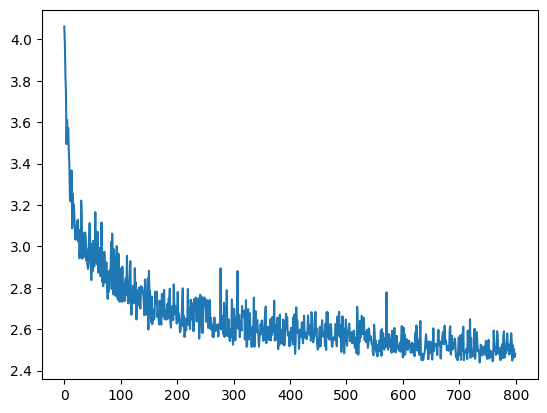

| | | | | | | | | | 

Epoch : 0 # 810
Loss: 2.485163688659668
--------------------
| | | | | | | | | | 

Epoch : 0 # 820
Loss: 2.4405581951141357
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 830
Loss: 2.4916021823883057
--------------------
| | | | | | | | | | 

Epoch : 0 # 840
Loss: 2.500112295150757
--------------------
| | | | | | | | | | 

Epoch : 0 # 850
Loss: 2.4872639179229736
--------------------
| | | | | | | | | | 

Epoch : 0 # 860
Loss: 2.5141103267669678
--------------------
| | | | | | | | | | 

Epoch : 0 # 870
Loss: 2.4769020080566406
--------------------
| | | | | | | | | | 

Epoch : 0 # 880
Loss: 2.480879783630371
--------------------
| | | | | | | | | | 

Epoch : 0 # 890
Loss: 2.559330701828003
--------------------
| | | | | | | | | | 

Epoch : 0 # 900
Loss: 2.455667495727539
--------------------


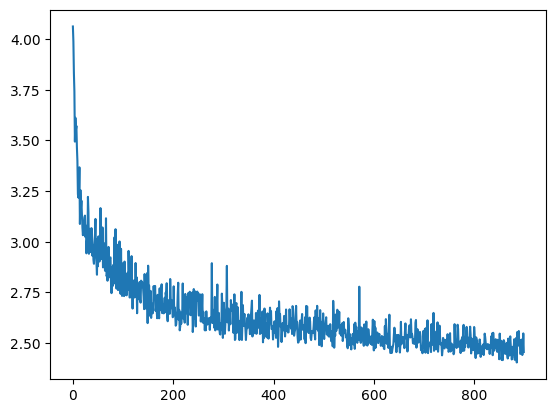

| | | | | | | | | | 

Epoch : 0 # 910
Loss: 2.4471755027770996
--------------------
| | | | | | | | | | 

Epoch : 0 # 920
Loss: 2.4808506965637207
--------------------
| | | | | | | | | | 

Epoch : 0 # 930
Loss: 2.4248127937316895
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 940
Loss: 2.481663227081299
--------------------
| | | | | | | | | | 

Epoch : 0 # 950
Loss: 2.457252264022827
--------------------
| | | | | | | | | | 

Epoch : 0 # 960
Loss: 2.57576584815979
--------------------
| | | | | | | | | | 

Epoch : 0 # 970
Loss: 2.420637845993042
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 980
Loss: 2.452971935272217
--------------------
| | | | | | | | | | 

Epoch : 0 # 990
Loss: 2.448883056640625
--------------------
| | | | | | | | | | 

Epoch : 0 # 1000
Loss: 2.494821071624756
--------------------


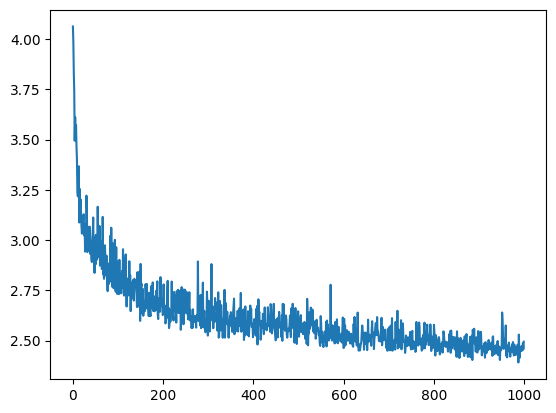

| | | | | | | | | | 

Epoch : 0 # 1010
Loss: 2.43186092376709
--------------------
| | | | | | | | | | 

Epoch : 0 # 1020
Loss: 2.462038993835449
--------------------
| | | | | | | | | | 

Epoch : 0 # 1030
Loss: 2.4682750701904297
--------------------
| | | | | | | | | | 

Epoch : 0 # 1040
Loss: 2.4102139472961426
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1050
Loss: 2.4854400157928467
--------------------
| | | | | | | | | | 

Epoch : 0 # 1060
Loss: 2.482375383377075
--------------------
| | | | | | | | | | 

Epoch : 0 # 1070
Loss: 2.4478423595428467
--------------------
| | | | | | | | | | 

Epoch : 0 # 1080
Loss: 2.3961846828460693
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1090
Loss: 2.5201127529144287
--------------------
| | | | | | | | | | 

Epoch : 0 # 1100
Loss: 2.4230093955993652
--------------------


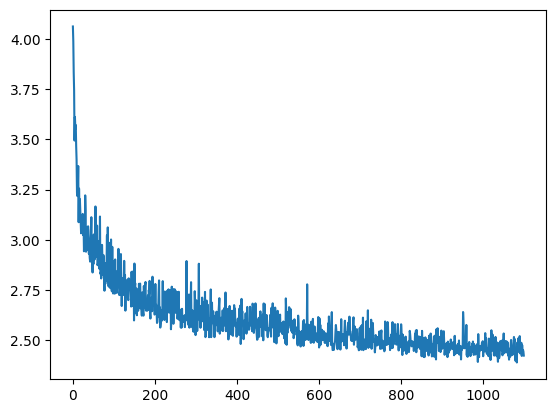

| | | | | | | | | | 

Epoch : 0 # 1110
Loss: 2.5064756870269775
--------------------
| | | | | | | | | | 

Epoch : 0 # 1120
Loss: 2.395090341567993
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1130
Loss: 2.439012050628662
--------------------
| | | | | | | | | | 

Epoch : 0 # 1140
Loss: 2.419602155685425
--------------------
| | | | | | | | | | 

Epoch : 0 # 1150
Loss: 2.4312171936035156
--------------------
| | | | | | | | | | 

Epoch : 0 # 1160
Loss: 2.4558463096618652
--------------------
| | | | | | | | | | 

Epoch : 0 # 1170
Loss: 2.489222288131714
--------------------
| | | | | | | | | | 

Epoch : 0 # 1180
Loss: 2.42875599861145
--------------------
| | | | | | | | | | 

Epoch : 0 # 1190
Loss: 2.4682388305664062
--------------------
| | | | | | | | | | 

Epoch : 0 # 1200
Loss: 2.3718628883361816
--------------------
saved SSLEncoder.pth
--------------------


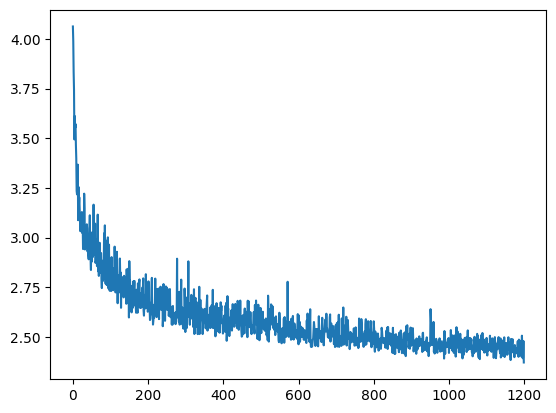

| | | | | | | | | | 

Epoch : 0 # 1210
Loss: 2.388230323791504
--------------------
| | | | | | | | | | 

Epoch : 0 # 1220
Loss: 2.3988099098205566
--------------------
| | | | | | | | | | 

Epoch : 0 # 1230
Loss: 2.410710334777832
--------------------
| | | | | | | | | | 

Epoch : 0 # 1240
Loss: 2.4601950645446777
--------------------
| | | | | | | | | | 

Epoch : 0 # 1250
Loss: 2.438877582550049
--------------------
| | | | | | | | | | 

Epoch : 0 # 1260
Loss: 2.4045958518981934
--------------------
| | | | | | | | | | 

Epoch : 0 # 1270
Loss: 2.415121555328369
--------------------
| | | | | | | | | | 

Epoch : 0 # 1280
Loss: 2.434799909591675
--------------------
| | | | | | | | | | 

Epoch : 0 # 1290
Loss: 2.4452285766601562
--------------------
| | | | | | | | | | 

Epoch : 0 # 1300
Loss: 2.4582905769348145
--------------------


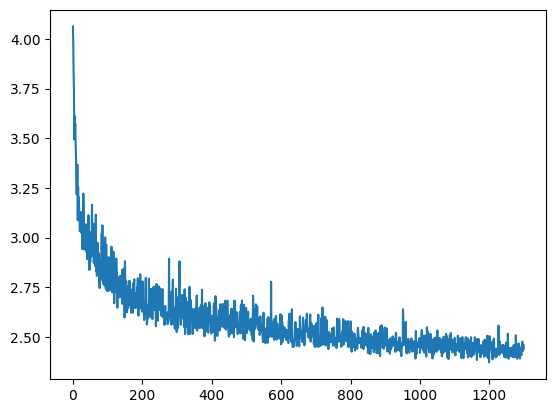

| | | | | | | | | | 

Epoch : 0 # 1310
Loss: 2.4271559715270996
--------------------
| | | | | | | | | | 

Epoch : 0 # 1320
Loss: 2.4468741416931152
--------------------
| | | | | | | | | | 

Epoch : 0 # 1330
Loss: 2.4570982456207275
--------------------
| | | | | | | | | | 

Epoch : 0 # 1340
Loss: 2.392479181289673
--------------------
| | | | | | | | | | 

Epoch : 0 # 1350
Loss: 2.4164559841156006
--------------------
| | | | | | | | | | 

Epoch : 0 # 1360
Loss: 2.461130142211914
--------------------
| | | | | | | | | | 

Epoch : 0 # 1370
Loss: 2.441786289215088
--------------------
| | | | | | | | | | 

Epoch : 0 # 1380
Loss: 2.443324327468872
--------------------
| | | | | | | | | | 

Epoch : 0 # 1390
Loss: 2.3849921226501465
--------------------
| | | | | | | | | | 

Epoch : 0 # 1400
Loss: 2.3932337760925293
--------------------


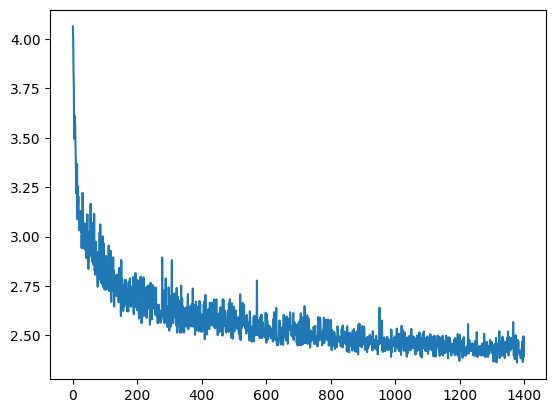

| | | | | | | | | | 

Epoch : 0 # 1410
Loss: 2.428680419921875
--------------------
| | | | | | | | | | 

Epoch : 0 # 1420
Loss: 2.4237124919891357
--------------------
| | | | | | | | | | 

Epoch : 0 # 1430
Loss: 2.464521884918213
--------------------
| | | | | | | | | | 

Epoch : 0 # 1440
Loss: 2.4030065536499023
--------------------
| | | | | | | | | | 

Epoch : 0 # 1450
Loss: 2.4126014709472656
--------------------
| | | | | | | | | | 

Epoch : 0 # 1460
Loss: 2.447550058364868
--------------------
| | | | | | | | | | 

Epoch : 0 # 1470
Loss: 2.405400276184082
--------------------
| | | | | | | | | | 

Epoch : 0 # 1480
Loss: 2.473353624343872
--------------------
| | | | | | | | | | 

Epoch : 0 # 1490
Loss: 2.400174140930176
--------------------
| | | | | | | | | | 

Epoch : 0 # 1500
Loss: 2.4105191230773926
--------------------


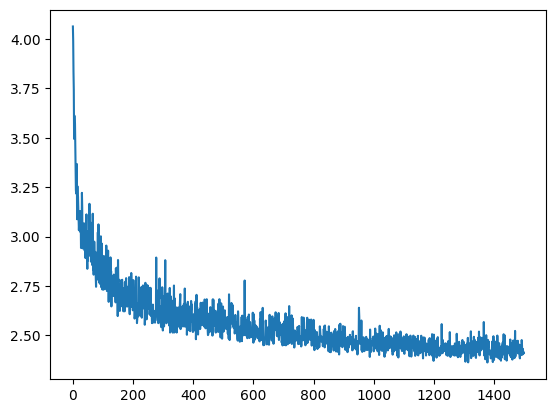

| | | | | | | | | | 

Epoch : 0 # 1510
Loss: 2.363600730895996
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1520
Loss: 2.4423558712005615
--------------------
| | | | | | | | | | 

Epoch : 0 # 1530
Loss: 2.458639621734619
--------------------
| | | | | | | | | | 

Epoch : 0 # 1540
Loss: 2.409219741821289
--------------------
| | | | | | | | | | 

Epoch : 0 # 1550
Loss: 2.4272069931030273
--------------------
| | | | | | | | | | 

Epoch : 0 # 1560
Loss: 2.4438459873199463
--------------------
| | | | | | | | | | 

Epoch : 0 # 1570
Loss: 2.414781093597412
--------------------
| | | | | | | | | | 

Epoch : 0 # 1580
Loss: 2.428495168685913
--------------------
| | | | | | | | | | 

Epoch : 0 # 1590
Loss: 2.4017231464385986
--------------------
| | | | | | | | | | 

Epoch : 0 # 1600
Loss: 2.3873989582061768
--------------------


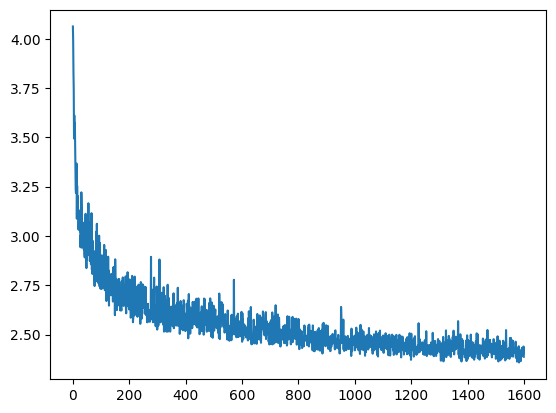

| | | | | | | | | | 

Epoch : 0 # 1610
Loss: 2.4081783294677734
--------------------
| | | | | | | | | | 

Epoch : 0 # 1620
Loss: 2.417833089828491
--------------------
| | | | | | | | | | 

Epoch : 0 # 1630
Loss: 2.3748176097869873
--------------------
| | | | | | | | | | 

Epoch : 0 # 1640
Loss: 2.4748411178588867
--------------------
| | | | | | | | | | 

Epoch : 0 # 1650
Loss: 2.3914103507995605
--------------------
| | | | | | | | | | 

Epoch : 0 # 1660
Loss: 2.4275436401367188
--------------------
| | | | | | | | | | 

Epoch : 0 # 1670
Loss: 2.400113105773926
--------------------
| | | | | | | | | | 

Epoch : 0 # 1680
Loss: 2.4208664894104004
--------------------
| | | | | | | | | | 

Epoch : 0 # 1690
Loss: 2.3913917541503906
--------------------
| | | | | | | | | | 

Epoch : 0 # 1700
Loss: 2.378653049468994
--------------------


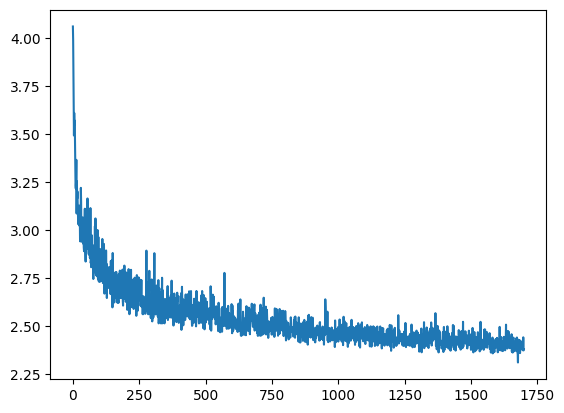

| | | | | | | | | | 

Epoch : 0 # 1710
Loss: 2.45127272605896
--------------------
| | | | | | | | | | 

Epoch : 0 # 1720
Loss: 2.4039196968078613
--------------------
| | | | | | | | | | 

Epoch : 0 # 1730
Loss: 2.421523332595825
--------------------
| | | | | | | | | | 

Epoch : 0 # 1740
Loss: 2.368785858154297
--------------------
| | | | | | | | | | 

Epoch : 0 # 1750
Loss: 2.4112229347229004
--------------------
| | | | | | | | | | 

Epoch : 0 # 1760
Loss: 2.3868496417999268
--------------------
| | | | | | | | | | 

Epoch : 0 # 1770
Loss: 2.411055088043213
--------------------
| | | | | | | | | | 

Epoch : 0 # 1780
Loss: 2.373552083969116
--------------------
| | | | | | | | | | 

Epoch : 0 # 1790
Loss: 2.4038186073303223
--------------------
| | | | | | | | | | 

Epoch : 0 # 1800
Loss: 2.379385471343994
--------------------


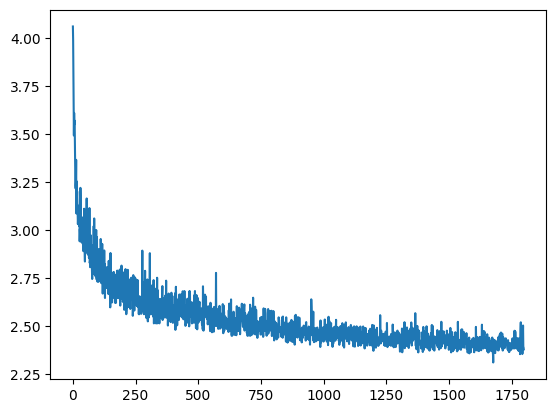

| | | | | | | | | | 

Epoch : 0 # 1810
Loss: 2.4309208393096924
--------------------
| | | | | | | | | | 

Epoch : 0 # 1820
Loss: 2.358499765396118
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1830
Loss: 2.380053758621216
--------------------
| | | | | | | | | | 

Epoch : 0 # 1840
Loss: 2.365511894226074
--------------------
| | | | | | | | | | 

Epoch : 0 # 1850
Loss: 2.3873956203460693
--------------------
| | | | | | | | | | 

Epoch : 0 # 1860
Loss: 2.4067726135253906
--------------------
| | | | | | | | | | 

Epoch : 0 # 1870
Loss: 2.3994622230529785
--------------------
| | | | | | | | | | 

Epoch : 0 # 1880
Loss: 2.4152164459228516
--------------------
| | | | | | | | | | 

Epoch : 0 # 1890
Loss: 2.4076061248779297
--------------------
| | | | | | | | | | 

Epoch : 0 # 1900
Loss: 2.406306028366089
--------------------


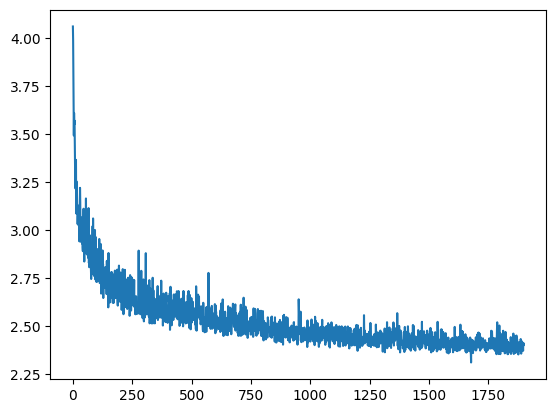

| | | | | | | | | | 

Epoch : 0 # 1910
Loss: 2.4089550971984863
--------------------
| | | | | | | | | | 

Epoch : 0 # 1920
Loss: 2.356278657913208
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1930
Loss: 2.366814613342285
--------------------
| | | | | | | | | | 

Epoch : 0 # 1940
Loss: 2.545132875442505
--------------------
| | | | | | | | | | 

Epoch : 0 # 1950
Loss: 2.411738872528076
--------------------
| | | | | | | | | | 

Epoch : 0 # 1960
Loss: 2.344334125518799
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1970
Loss: 2.3990635871887207
--------------------
| | | | | | | | | | 

Epoch : 0 # 1980
Loss: 2.3872714042663574
--------------------
| | | | | | | | | | 

Epoch : 0 # 1990
Loss: 2.3696229457855225
--------------------
| | | | | | | | | | 

Epoch : 0 # 2000
Loss: 2.368551015853882
--------------------


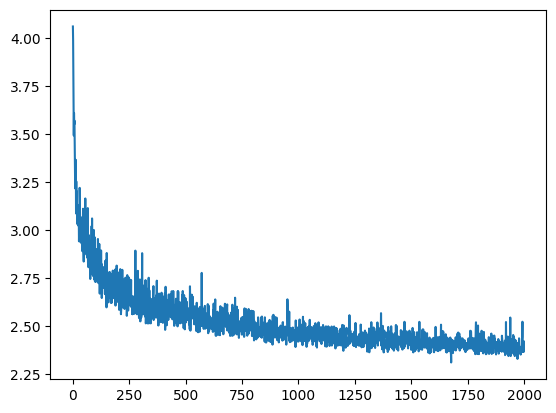

| | | | | | | | | | 

Epoch : 0 # 2010
Loss: 2.368403434753418
--------------------
| | | | | | | | | | 

Epoch : 0 # 2020
Loss: 2.375601291656494
--------------------
| | | | | | | | | | 

Epoch : 0 # 2030
Loss: 2.377824544906616
--------------------
| | | | | | | | | | 

Epoch : 0 # 2040
Loss: 2.3997585773468018
--------------------
| | | | | | | | | | 

Epoch : 0 # 2050
Loss: 2.3416588306427
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 2060
Loss: 2.3686132431030273
--------------------
| | | | | | | | | | 

Epoch : 0 # 2070
Loss: 2.4485983848571777
--------------------
| | | | | | | | | | 

Epoch : 0 # 2080
Loss: 2.4016499519348145
--------------------
| | | | | | | | | | 

Epoch : 0 # 2090
Loss: 2.445112943649292
--------------------
| | | | | | | | | | 

Epoch : 0 # 2100
Loss: 2.3422329425811768
--------------------


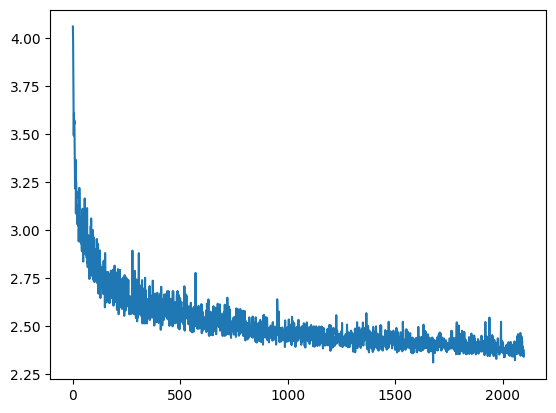

| | | | | | | | | | 

Epoch : 0 # 2110
Loss: 2.3556971549987793
--------------------
| | | | | | | | | | 

Epoch : 0 # 2120
Loss: 2.376703977584839
--------------------
| | | | | | | | | | 

Epoch : 0 # 2130
Loss: 2.3759963512420654
--------------------
| | | | | | | | | | 

Epoch : 0 # 2140
Loss: 2.388066291809082
--------------------
| | | | | | | | | | 

Epoch : 0 # 2150
Loss: 2.3600826263427734
--------------------
| | | | | | | | | | 

Epoch : 0 # 2160
Loss: 2.3645706176757812
--------------------
| | | | | | | | | | 

Epoch : 0 # 2170
Loss: 2.3607115745544434
--------------------
| | | | | | | | | | 

Epoch : 0 # 2180
Loss: 2.3733482360839844
--------------------
| | | | | | | | | | 

Epoch : 0 # 2190
Loss: 2.365494728088379
--------------------
| | | | | | | | | | 

Epoch : 0 # 2200
Loss: 2.346041202545166
--------------------


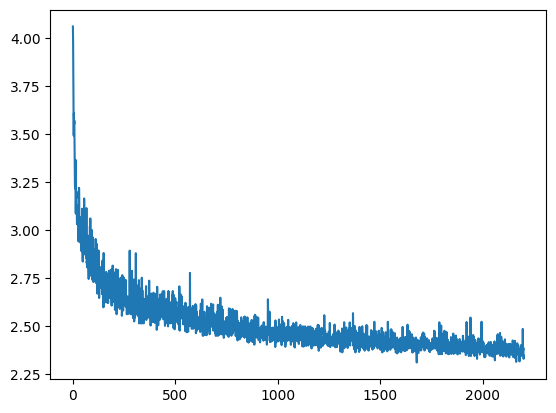

| | | | | | | | | | 

Epoch : 0 # 2210
Loss: 2.3687422275543213
--------------------
| | | | | | | | | | 

Epoch : 0 # 2220
Loss: 2.402730703353882
--------------------
| | | | | | | | | | 

Epoch : 0 # 2230
Loss: 2.381711959838867
--------------------
| | | | | | | | | | 

Epoch : 0 # 2240
Loss: 2.3584821224212646
--------------------
| | | | | | | | | | 

Epoch : 0 # 2250
Loss: 2.342134475708008
--------------------
| | | | | | | | | | 

Epoch : 0 # 2260
Loss: 2.362173318862915
--------------------
| | | | | | | | | | 

Epoch : 0 # 2270
Loss: 2.311735153198242
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 2280
Loss: 2.324744701385498
--------------------
| | | | | | | | | | 

Epoch : 0 # 2290
Loss: 2.41281795501709
--------------------
| | | | | | | | | | 

Epoch : 0 # 2300
Loss: 2.369826316833496
--------------------


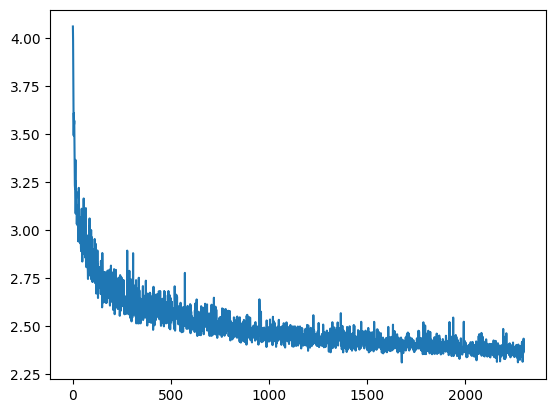

| | | | | | | | | | 

Epoch : 0 # 2310
Loss: 2.377072334289551
--------------------
| | | | | | | | | | 

Epoch : 0 # 2320
Loss: 2.3911452293395996
--------------------
| | | | 

In [ ]:
epochs=2
min_loss=None
for epoch in range(epochs):
    c=0
    l=[]
    for v1,v2 in my_dataloader:
        v1,v2=v1.to(device),v2.to(device)
        optim.zero_grad()
        with torch.autocast(device_type='cuda', enabled=(device.type == "cuda")):
            h1,z1=SSLEncoder(v1)
            h2,z2=SSLEncoder(v2)

            z=torch.stack([z1,z2],dim=1).reshape(-1,z1.shape[-1])

            loss=NTXent_Loss(z,tau=0.5)

            loss.backward()

            optim.step()

        l.append(loss.item())

        c+=1
        print("|",end=" ")
        if c%10==0:
            print("\n")
            print(f"Epoch : {epoch} # {c}")
            print(f"Loss: {loss.item()}")
            print("-"*20)
            if(min_loss is None or loss.item()<min_loss):
                min_loss=loss.item()
                torch.save(SSLEncoder.state_dict(),"/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/SSLEncoder.pth")
                print("saved SSLEncoder.pth")
                print("-"*20)
            if c%100==0:
                plt.plot(l)
                plt.show()
    loss_dict[epoch]=l

In [ ]:
# loss_dict

In [ ]:
SSLEncoder.load_state_dict(torch.load('/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/SSLEncoder.pth',weights_only=True))

## Linear Layer

In [ ]:
class Linear_Layer(nn.Module):
    def __init__(self,input_dim=512):
        super().__init__()
        self.ll=nn.Sequential(
            nn.Linear(in_features=input_dim,out_features=64),
            nn.ReLU(),

            nn.Linear(in_features=64,out_features=1),
            # nn.Softmax(dim=1),
            # nn.Sigmoid()
        )
    def forward(self,h):
        return self.ll(h)

In [ ]:
Final_Layer=Linear_Layer()
optimizer_FL=torch.optim.AdamW(Final_Layer.parameters(),lr=1e-5,weight_decay=1e-4)

## Encoder weights freezing

In [ ]:
for param in SSLEncoder.parameters():
    param.requires_grad=False

## Linear layer training

In [ ]:
label_percent=[1,5,10,100]

In [ ]:
epochs=5
loss_dict_FL={}
lossFn=nn.BCEWithLogitsLoss()
SSLEncoder.eval()
label_percentwise_metrics={}
for lp in label_percent:
    linear_DS=DT(layer_list,True,labels,p=lp)
    DL=DataLoader(
    dataset=linear_DS,
    batch_size=64,
    shuffle=True,
    num_workers=4,
    pin_memory=False,
    persistent_workers=True
    )
    Final_Layer = Linear_Layer().to(device)
    optimizer_FL=torch.optim.AdamW(Final_Layer.parameters(),lr=1e-5,weight_decay=1e-4)
    # d={}
    min_loss=None
    l=[]
    for epoch in range(epochs):
        c=0
        y_result_accumulated=torch.tensor([]).to(device)
        y_real_accumulated=torch.tensor([]).to(device)
        for x,y in DL:
            x,y=x.to(device),y.to(device)
            optimizer_FL.zero_grad()
            with torch.no_grad():
                h,_=SSLEncoder(x)

            y_result=Final_Layer(h).squeeze(1)
            loss=lossFn(y_result,y.float())
            loss.backward()
            optimizer_FL.step()
            c+=1
            y_result=torch.sigmoid(y_result)
            l.append(loss.item())
            y_result_accumulated=torch.cat([y_result_accumulated,y_result])
            y_real_accumulated=torch.cat([y_real_accumulated,y])
            if min_loss is None: min_loss=loss.item()
            print("|",end=" ")
            if(c%10==0):
                print("\n")
                print(f"Epoch : {epoch} # {c}")
                print(f"Loss: {loss.item()}")
                metrics_display(y_real=y,y_result=y_result)
                print("-"*20)
                if(loss.item()<min_loss):
                    min_loss=loss.item()
                    addr=f"/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/Final_Layer_p{lp}.pth"
                    torch.save(Final_Layer.state_dict(),addr)
                if c%100==0:
                    plt.plot(l)
                    plt.show()
        print("-"*20)
        print(f"Epoch#{epoch}")
        metrics_display(y_real=y_real_accumulated,y_result=y_result_accumulated)
        print("-"*20)

    loss_dict_FL[lp]=l
    label_percentwise_metrics[lp]=metrics_dict_creator(y_real=y_real_accumulated,y_result=y_result_accumulated)

In [ ]:
plt.figure()
for lp in loss_dict_FL:
    plt.plot(loss_dict_FL[lp])
plt.show()

In [ ]:
label_percentwise_metrics_df=pd.DataFrame(label_percentwise_metrics)
print(label_percentwise_metrics_df)

## Base Line Model
- Resnet trained directly without SSL training

In [ ]:
BLEncoder=Encoder().to(device)
BLFinal_Layer=Linear_Layer().to(device)
optimizer_BL=torch.optim.AdamW(itertools.chain(BLEncoder.parameters(), BLFinal_Layer.parameters()),lr=1e-5,weight_decay=1e-4)


### Baseline Model training loop

In [ ]:
epochs=5
loss_dict_FL={}
lossFn=nn.BCELoss()

linear_DS=DT(layer_list,True,labels,p=100)
DL=DataLoader(
    dataset=linear_DS,
    batch_size=64,
    shuffle=True,
    num_workers=4,
    pin_memory=False,
    persistent_workers=True
  )

    # optimizer_FL=torch.optim.AdamW(Final_Layer.parameters(),lr=1e-5,weight_decay=1e-4)
    # d={}
min_loss=None
l=[]
for epoch in range(epochs):
    c=0
    y_result_accumulated=torch.tensor([]).to(device)
    y_real_accumulated=torch.tensor([]).to(device)
    for x,y in DL:
        x,y=x.to(device),y.to(device)
        optimizer_BL.zero_grad()

        h,_=BLEncoder(x)
        y_result=BLFinal_Layer(h).squeeze(1)
        loss=lossFn(y_result,y.float())
        loss.backward()
        optimizer_BL.step()
        c+=1
        l.append(loss.item())
        y_result=torch.sigmoid(y_result)
        y_result_accumulated=torch.cat([y_result_accumulated,y_result])
        y_real_accumulated=torch.cat([y_real_accumulated,y])
        print("|",end=" ")
        if(c%10==0):
            print("\n")
            print(f"Epoch : {epoch} # {c}")
            print(f"Loss: {loss.item()}")
            metrics_display(y_real=y,y_result=y_result)
            print("-"*20)
            if(min_loss is None or loss.item()<=min_loss):
                min_loss=loss.item()
                addr="/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/BLFinal_Layer.pth"
                torch.save(BLFinal_Layer.state_dict(),addr)
                addr="/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/BLEncoder.pth"
                torch.save(BLEncoder.state_dict(),addr)
            if c%100==0:
                plt.plot(l)
                plt.show()
        # d[epoch]=l
    print("-"*20)
    print(f"Epoch#{epoch}")
    metrics_display(y_real=y_real_accumulated,y_result=y_result_accumulated)
    print("-"*20)

loss_dict_BL=l


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Evaluation of Baseline and the Model on Eval dataset

### Baseline evaluation


In [ ]:
DL=DataLoader(
    dataset=eval_DS,
    batch_size=64,
    shuffle=True,
    num_workers=4,
    pin_memory=False,
    persistent_workers=True
  )

y_result_accumulated=torch.tensor([]).to(device)
y_real_accumulated=torch.tensor([]).to(device)
for x,y in DL:
    x,y=x.to(device),y.to(device)
    with torch.no_grad():
        h,_=BLEncoder(x)
        y_result=BLFinal_Layer(h).squeeze(1)
    y_result=torch.sigmoid(y_result)
    y_result_accumulated=torch.cat([y_result_accumulated,y_result])
    y_real_accumulated=torch.cat([y_real_accumulated,y])
    print("|",end=" ")
metrics_display(y_real=y_real_accumulated,y_result=y_result_accumulated)
BL_metrics=metrics_dict_creator(y_real=y_real_accumulated,y_result=y_result_accumulated)
BL_metrics_df=pd.DataFrame(BL_metrics,index=[0])


In [ ]:
BL_metrics_df

NameError: name 'BL_metrics_df' is not defined

In [ ]:
BL_metrics.to_csv("/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/BL_metrics.csv")

### Model


In [ ]:
for lp in label_percent:
    addr=f"/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/Final_Layer_p{lp}.pth"
    Final_Layer.load_state_dict(torch.load(addr,weights_only=True))
    DL=DataLoader(
        dataset=eval_DS,
        batch_size=64,
        shuffle=True,
        num_workers=4,
        pin_memory=False,
        persistent_workers=True
    )